# ML Lab 2: Frame the Price Prediction Problem and Prepare the Dataset
**Company:** AutoVision Analytics | **Role:** Junior Data Scientist | **Dataset:** `Automobile_data.csv`

### Business scenario (in simple words)
The company wants a **Vehicle Price Prediction System**. Think of how Cars24 or OLX Autos shows you an estimated price after you enter your car's details. Before any ML model can be built, the data must be **understood, cleaned and converted into numbers**. That is today's job.

### What we will do today
| Task | What | Why |
|---|---|---|
| 1 | Frame the problem (target vs features) | Know *what* we predict and *using what* |
| 2 | Load and explore the data | Know what data we have |
| 3 | Analyze feature distributions | Spot skew and outliers early |
| 4 | Improve data quality (missing, duplicates, outliers) | Models give bad results on dirty data |
| 5 | Encode categorical data | Models only understand numbers |

> **Golden rule:** *Garbage in, garbage out.* A good model on bad data still gives bad predictions.

## Task 1: Frame the Price Prediction Problem

### Concept: Target Variable
**Definition:** The **target variable** is the value we want the model to predict. It is also called the *label*, *dependent variable* or *y*.

**Real-life example:** On a house-selling app the target is the **house price**. In a bank loan app it is *"will the customer repay: yes or no?"*.

**Here:** Target = `price` of the car.

### Concept: Features
**Definition:** **Features** are the input columns the model uses to make the prediction. They are also called *independent variables* or *X*.

**Real-life example:** A used-car dealer in Pune decides the price by looking at the engine size, the mileage, the brand and the body type. Those are the features. The final price is the target.

### Which ML approach?
Price is a **continuous number** (for example 7,500 or 16,000), so this is a **Regression** problem. If we had predicted "cheap / medium / expensive" it would be Classification.

### Activity table: Feature or Target?
| Column name | Feature / Target Variable | Why |
|---|---|---|
| `price` | **Target Variable** | This is what we want to predict |
| `horsepower` | **Feature** | More power usually means a costlier car |
| `engine-size` | **Feature** | Bigger engine usually means a higher price |
| `fuel-type` | **Feature** | Petrol (gas) and diesel cars are priced differently |
| `city-mpg` | **Feature** | Mileage in city traffic is a buying factor, as in India |

### Dataset dictionary (what each column means)
| Column | Meaning | Type | Real-life analogy |
|---|---|---|---|
| `symboling` | Insurance risk rating. +3 is risky, -3 is safe | Number (but really a category) | Like an insurance company's risk grade |
| `normalized-losses` | Average yearly insurance loss, relative to other cars | Number | How much the insurer pays out for this car type |
| `make` | Brand | Category | Maruti, Hyundai, Tata |
| `fuel-type` | gas or diesel | Category | Petrol or Diesel |
| `body-style` | sedan, hatchback, wagon, etc. | Category | Dzire (sedan) vs Swift (hatchback) |
| `drive-wheels` | fwd, rwd or 4wd | Category | Which wheels get the engine power |
| `engine-location` | front or rear | Category | Engine position in the car |
| `width`, `height` | Car size (inches) | Number | Whether the car fits in your parking |
| `engine-type` | ohc, dohc, rotor and so on | Category | Engine design |
| `engine-size` | Engine capacity (cubic inches) | Number | Like 1000cc vs 1500cc |
| `horsepower` | Engine power | Number | How strongly the car accelerates |
| `city-mpg`, `highway-mpg` | Miles per gallon in city or on the highway | Number | Same idea as km/l |
| `price` | Selling price | Number (**Target**) | What the car is sold for |

## Task 2: Load and Explore the Dataset

Before cleaning anything, we first *look* at the data. It is like a doctor checking the patient's reports before giving medicine.

**Using Google Colab:** open Colab, create a new notebook and rename it. Click the **Files** icon on the left, upload `Automobile_data.csv` and check that it appears there.

### Step 1: Import the libraries
| Library | What it does | Use case here |
|---|---|---|
| `pandas` (`pd`) | Works with tables (rows and columns) | Load the CSV, clean it, filter it |
| `numpy` (`np`) | Fast number operations and the `NaN` (missing value) symbol | Mark missing values, select numeric columns |

**Real-life example:** pandas is like Excel inside Python, and numpy is like the calculator behind it.

In [1]:
import pandas as pd
import numpy as np

### Step 2: Load the dataset
**Function:** `pd.read_csv("file.csv")`
- **Definition:** Reads a CSV (comma-separated) file and creates a **DataFrame** (a table).
- **Use case:** Our automobile data is stored as a CSV, so this puts it into Python.
- **Real-life example:** It is like opening an Excel file, except the data now lives in the variable `df`.

> In Colab the file is in the same folder, so we use just the file name. On your laptop give the full path if needed.

In [2]:
df = pd.read_csv("Automobile_data.csv")
print("Dataset loaded. Rows, Columns =", df.shape)

Dataset loaded. Rows, Columns = (205, 15)


### Step 3: Display the first five records
**Function:** `df.head()`
- **Definition:** Shows the first 5 rows (you can pass a number, for example `df.head(10)`).
- **Use case:** A quick sanity check that the file loaded correctly and the columns look right.
- **Real-life example:** Like flipping through the first page of a register to see what is inside.

**Look for:** the `?` symbols in `normalized-losses`. This dataset uses `?` for missing values. We will fix them in Task 4.

In [3]:
df.head()

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,?,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450


### Step 4: Dataset information
**Function:** `df.info()`
- **Definition:** Prints a summary of the structure: number of rows, each column name, **non-null count** and **data type (Dtype)**.
- **Use case:** It shows which columns are numeric and which are text. It also exposes wrong data types.
- **Real-life example:** Like a stock register that says how many items are in each shelf and what kind they are.

**What to notice:** `normalized-losses` and `horsepower` should be numbers, but they show as text (`object` or `str`) because of the `?` values. This is a data-quality problem.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    str    
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   body-style         205 non-null    str    
 5   drive-wheels       205 non-null    str    
 6   engine-location    205 non-null    str    
 7   width              205 non-null    float64
 8   height             205 non-null    float64
 9   engine-type        205 non-null    str    
 10  engine-size        205 non-null    int64  
 11  horsepower         205 non-null    str    
 12  city-mpg           205 non-null    int64  
 13  highway-mpg        205 non-null    int64  
 14  price              205 non-null    int64  
dtypes: float64(2), int64(5), str(8)
memory usage: 24.2 KB


### Step 5: Statistical summary
**Function:** `df.describe()`
- **Definition:** Gives count, mean, std, min, 25%, 50% (median), 75% and max for every **numeric** column.
- **Use case:** It shows the typical value, the spread and a hint of outliers. If max is far bigger than the 75% value, the column may have outliers.
- **Real-life example:** Like a cricket scorecard summary of a batsman: average, highest score and consistency.

| Row | Meaning | Example |
|---|---|---|
| `count` | How many non-missing values | Students who attended |
| `mean` | Average | Average marks |
| `std` | How spread out the values are | Do all students score similar marks? |
| `min / max` | Smallest / largest | Lowest / highest marks |
| `25% / 50% / 75%` | Quartiles. 50% is the median | The middle student's marks is the 50% |

In [5]:
df.describe()

,symboling,width,height,engine-size,city-mpg,highway-mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,65.907805,53.724878,126.907317,25.219512,30.751220,13227.478049
std,1.245307,2.145204,2.443522,41.642693,6.542142,6.886443,7902.651615
min,-2.000000,60.300000,47.800000,61.000000,13.000000,16.000000,5118.000000
25%,0.000000,64.100000,52.000000,97.000000,19.000000,25.000000,7788.000000
50%,1.000000,65.500000,54.100000,120.000000,24.000000,30.000000,10345.000000
75%,2.000000,66.900000,55.500000,141.000000,30.000000,34.000000,16500.000000
max,3.000000,72.300000,59.800000,326.000000,49.000000,54.000000,45400.000000


## Task 3: Analyze Feature Distributions

**Definition:** A **distribution** shows how often each value (or range of values) occurs in a column.

**Why it matters:** The shape of the data tells us how to clean it:
- **Skewed data:** use the *median* to fill missing values.
- **Outliers:** extreme values that can mislead the model.
- **Business insight:** for example, most cars are cheap and only a few are luxury.

**Real-life example:** Look at the salaries in an Indian IT company. Most people earn 4 to 10 LPA, but a few leaders earn 1 crore or more. The graph has a long tail on the right. This is **right-skewed** data.

### Function used: `df['column'].hist()`
- **Definition:** Draws a **histogram**. It splits values into ranges (bins) and shows a bar for the number of records in each range.
- **Use case:** To see the shape (symmetric, skewed), the most common range and any extreme values.
- **Real-life example:** A school teacher plots how many students fall in 0-10, 10-20, ... 90-100 marks.

> `?` values have not been fixed yet. To plot `price`, `engine-size` and `city-mpg` (already numeric) this is fine. `horsepower` has `?` in 2 rows, so we plot it after a temporary conversion, only for viewing.

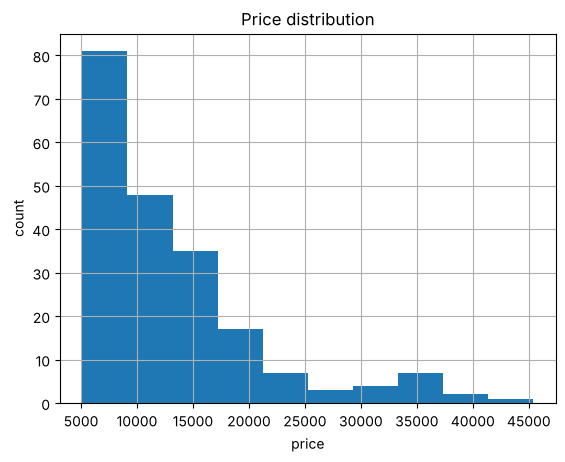

In [6]:
import matplotlib.pyplot as plt

# price
df['price'].hist()
plt.title('Price distribution'); plt.xlabel('price'); plt.ylabel('count'); plt.show()

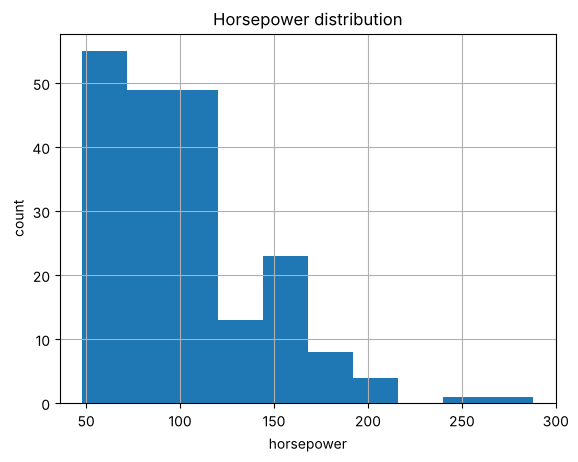

In [7]:
# horsepower (temporary numeric copy only for plotting, because the column still has '?')
pd.to_numeric(df['horsepower'], errors='coerce').hist()
plt.title('Horsepower distribution'); plt.xlabel('horsepower'); plt.ylabel('count'); plt.show()

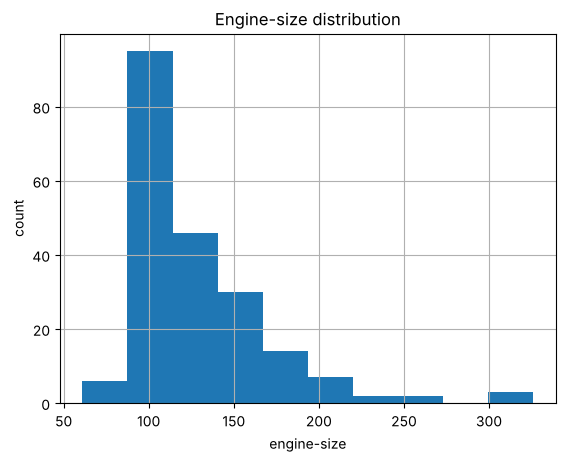

In [8]:
# engine-size
df['engine-size'].hist()
plt.title('Engine-size distribution'); plt.xlabel('engine-size'); plt.ylabel('count'); plt.show()

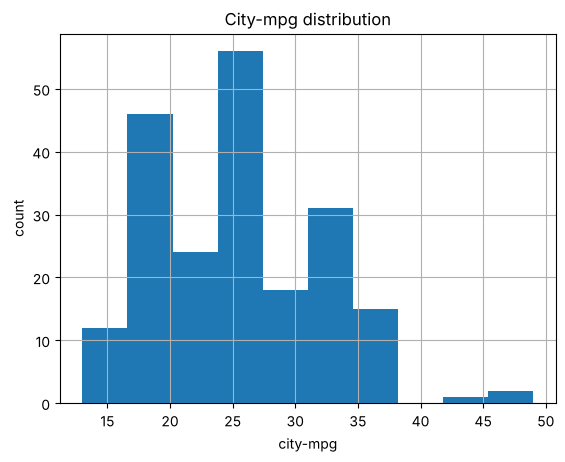

In [9]:
# city-mpg
df['city-mpg'].hist()
plt.title('City-mpg distribution'); plt.xlabel('city-mpg'); plt.ylabel('count'); plt.show()

### Activity: Record your observations
| Column | Observation | Simple meaning |
|---|---|---|
| **Price** | Right-skewed. Most cars cost about 5,000 to 15,000. A few luxury cars go up to about 45,000. | Many affordable cars, very few premium ones, like Maruti vs Mercedes in India |
| **Horsepower** | Right-skewed. Most cars have 60 to 120 hp. A few sports cars reach about 288 hp. | Most cars are everyday cars, a few are performance cars |
| **Engine-size** | Right-skewed. Most engines are 90 to 150. A few are very big (above 300). | Most are small to medium engines, very few are huge |
| **City-mpg** | Mildly right-skewed. Most cars give 20 to 35 mpg. A few very efficient ones give about 49. | Most cars have average mileage, a few are highly fuel-efficient |

**Takeaway:** All four have a long right tail. That means outliers may exist, and the **median** is safer than the mean for filling missing values.

## Task 4: Improve Data Quality

Dirty data lowers model accuracy. We fix three things in order: **missing values**, **duplicates** and **outliers**.

### Step 1: Standardize the dataset (replace `?` with NaN)
**Function:** `df.replace("?", np.nan, inplace=True)`
- **Definition:** Replaces every `?` in the table with `np.nan`, Python's real "missing value" symbol.
- **Use case:** pandas does not know that `?` means missing. After this it can detect, count and fill the gaps.
- **Attribute `inplace=True`:** Changes `df` directly and does not create a new copy.
- **Real-life example:** In a form, people write "NA", "-" or "?" when they don't know the answer. We convert all of them to one standard "blank".

In [10]:
df.replace("?", np.nan, inplace=True)
df.head()

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,NaN,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,NaN,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450


### Step 2: Convert columns to numeric
**Function:** `pd.to_numeric(series, errors="coerce")`
- **Definition:** Converts a column from text to numbers.
- **Attribute `errors="coerce"`:** If a value cannot be converted, it becomes `NaN` instead of crashing. (Other options: `"raise"` stops with an error, `"ignore"` leaves it as it is.)
- **Use case:** `normalized-losses` and `horsepower` were stored as text because of the `?`. We cannot calculate a mean or median on text.
- **Real-life example:** Like a bank clerk typing "Rs. 5,000" as text. Excel can't add it until it is converted to the number 5000.

In [11]:
df["normalized-losses"] = pd.to_numeric(df["normalized-losses"], errors="coerce")
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               205 non-null    str    
 3   fuel-type          205 non-null    str    
 4   body-style         205 non-null    str    
 5   drive-wheels       205 non-null    str    
 6   engine-location    205 non-null    str    
 7   width              205 non-null    float64
 8   height             205 non-null    float64
 9   engine-type        205 non-null    str    
 10  engine-size        205 non-null    int64  
 11  horsepower         203 non-null    float64
 12  city-mpg           205 non-null    int64  
 13  highway-mpg        205 non-null    int64  
 14  price              205 non-null    int64  
dtypes: float64(4), int64(5), str(6)
memory usage: 24.2 KB


### Step 3: Handle missing values
#### 3a. Count the nulls in each column
**Function:** `df.isnull().sum()`
- `isnull()` marks each cell `True` if it is missing and `False` otherwise.
- `sum()` adds the `True` values (True counts as 1), giving the missing count per column.
- **Real-life example:** Counting the empty seats in each row of a cinema hall.

In [12]:
df.isnull().sum()

symboling             0
normalized-losses    41
make                  0
fuel-type             0
body-style            0
drive-wheels          0
engine-location       0
width                 0
height                0
engine-type           0
engine-size           0
horsepower            2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

**Result:** `normalized-losses` has **41** missing values (about 20%). `horsepower` has **2**. Everything else is complete.

#### 3b. Plot a histogram to check skewness
**Why check skewness first?** It decides how we fill the gaps.
| Data shape | Best fill | Why |
|---|---|---|
| Symmetric (skew close to 0) | **Mean** | The average is a fair "typical" value |
| Skewed (skew far from 0) | **Median** | Extreme values don't drag the median |

**Real-life example:** If 9 people earn 30,000 and one earns 10 lakh, the mean salary looks like about 1 lakh. That does not describe the group, but the median (30,000) does.

**Functions and attributes used in the plot:**
| Code | Meaning / use |
|---|---|
| `plt.figure(figsize=(8,5))` | Sets the chart size (width, height in inches) |
| `sns.histplot(data=df, x='col', bins=20, kde=True)` | Draws a histogram using seaborn. `x` is the column, `bins` is the number of bars and `kde=True` adds a smooth curve showing the shape |
| `plt.title / xlabel / ylabel` | Adds a title and axis labels so anyone can read the chart |
| `plt.show()` | Displays the chart |
| `df['col'].skew()` | Skewness value. About 0 means symmetric, positive means right tail, negative means left tail. Beyond ±0.5 is usually treated as skewed |
| `round(x, 3)` | Rounds to 3 decimal places for a clean print |

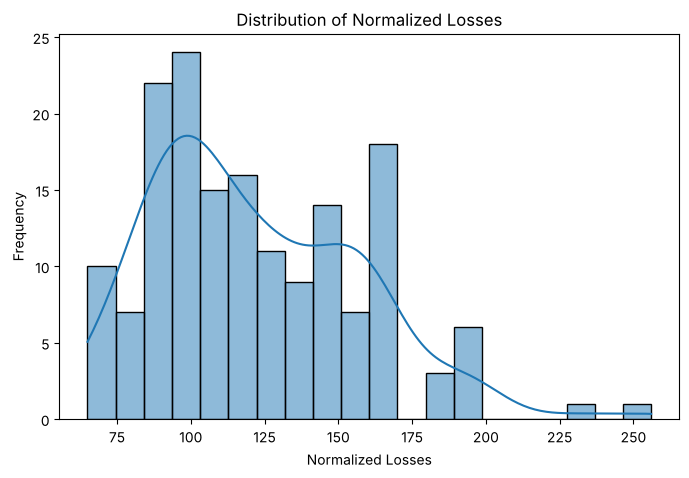

Skewness of Normalized Losses: 0.766


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(data=df, x='normalized-losses', bins=20, kde=True)
plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')
plt.show()

# Skewness value
print("Skewness of Normalized Losses:", round(df['normalized-losses'].skew(), 3))

#### 3c. Fill missing `normalized-losses` using the right central tendency
The skewness is positive (about 0.77), so the data is right-skewed. We use the **median**.

**Function:** `df['col'].fillna(value)`
- **Definition:** Replaces `NaN` with the value you give.
- **Use case:** Keeps all 205 rows instead of deleting rows with missing data.
- **Real-life example:** If a student's marks are missing, the teacher enters the class median as a temporary placeholder.

**Function:** `df['col'].median()` gives the middle value of the sorted data and ignores NaN automatically.

> **Note:** The lab uses `fillna(..., inplace=True)` on a single column. In newer pandas versions that style shows a warning, so we assign the result back instead. The output is the same.

In [14]:
df['normalized-losses'] = df['normalized-losses'].fillna(df['normalized-losses'].median())
print("Missing in normalized-losses:", df['normalized-losses'].isnull().sum())

Missing in normalized-losses: 0


#### 3d. Plot the histogram again (after filling)
This is the "after" picture. You will see a tall bar near the median (115), because 41 values were filled with the same number. This is a known side effect of median imputation, and it is the price we pay for keeping the rows.

> The lab's step (d) repeats the same code for `normalized-losses`. Since `horsepower` is the other column with missing values, we plot both below, so you can compare them.

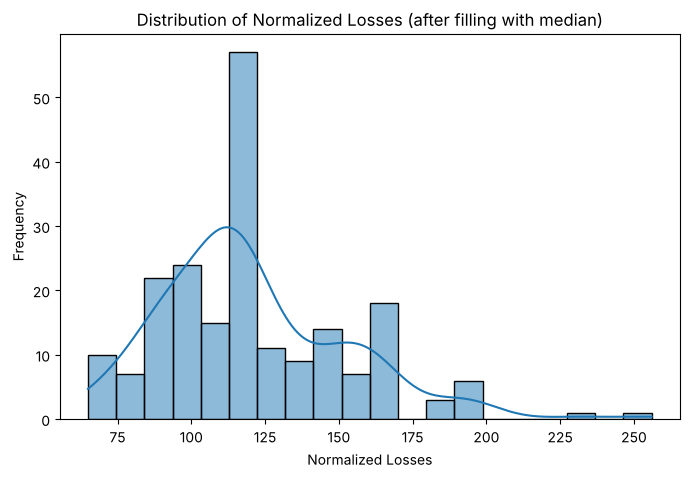

Skewness of Normalized Losses: 0.976


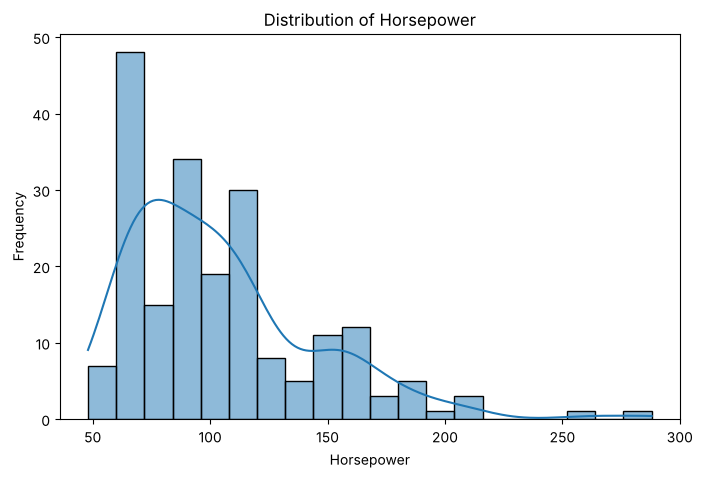

Skewness of Horsepower: 1.391


In [15]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='normalized-losses', bins=20, kde=True)
plt.title('Distribution of Normalized Losses (after filling with median)')
plt.xlabel('Normalized Losses'); plt.ylabel('Frequency'); plt.show()
print("Skewness of Normalized Losses:", round(df['normalized-losses'].skew(), 3))

# Horsepower (still has 2 missing values) - check skewness before filling
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='horsepower', bins=20, kde=True)
plt.title('Distribution of Horsepower'); plt.xlabel('Horsepower'); plt.ylabel('Frequency'); plt.show()
print("Skewness of Horsepower:", round(df['horsepower'].skew(), 3))

#### 3e. Fill missing `horsepower` with the median
Horsepower skewness is about 1.39, which is strongly right-skewed, so the **median** is the right choice. Only 2 values are missing, so the impact is tiny.

In [16]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

#### 3f. Verify that no values are missing

In [17]:
df.isnull().sum()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
body-style           0
drive-wheels         0
engine-location      0
width                0
height               0
engine-type          0
engine-size          0
horsepower           0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

**Expected:** every column shows `0`. If any column still shows a number, go back to that column's fill step.

### Step 4: Check duplicate records
**Function:** `df.duplicated().sum()`
- **Definition:** `duplicated()` marks a row `True` if an exactly identical row appeared earlier. `sum()` counts them.
- **Use case:** Duplicate rows make the model see the same car twice and become over-confident.
- **If duplicates exist:** remove them with `df.drop_duplicates(inplace=True)`.
- **Real-life example:** A customer registered twice on a shopping app with the same details. Counting both would inflate the customer count.

In [18]:
df.duplicated().sum()

np.int64(0)

**Result: 0.** There are no duplicate rows, so nothing to remove.

### Step 5: Handle the outliers
**Definition:** An **outlier** is a value far away from the rest of the data.

**Real-life example:** In a class where marks are about 60 to 80, one student scoring 2 (absent, wrongly entered) or a Rs. 3 crore luxury car in a Rs. 5-10 lakh car list. Such points can pull the model in the wrong direction.

#### 5a. Boxplots for the numeric columns
**Function:** `sns.boxplot(x=df[col])`
- **Definition:** A boxplot shows the box (25% to 75%, the middle half of the data), a line for the median and **whiskers**. Points beyond the whiskers (dots) are potential outliers.
- **Use case:** To spot outliers quickly.

**Other code used:**
| Code | Meaning / use |
|---|---|
| `df.select_dtypes(include=np.number).columns` | Picks only the numeric column names, because boxplots need numbers |
| `for col in num_cols:` | Repeats the same plot for each numeric column, instead of writing it 9 times |
| `plt.figure(figsize=(8,3))` | Wide and short chart size, suitable for a horizontal boxplot |
| `f'Boxplot of {col}'` | An f-string, which puts the column name in the title automatically |

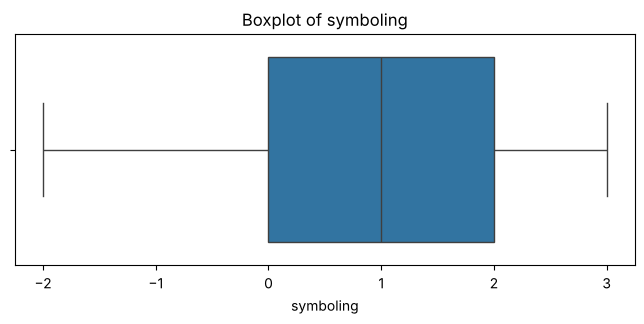

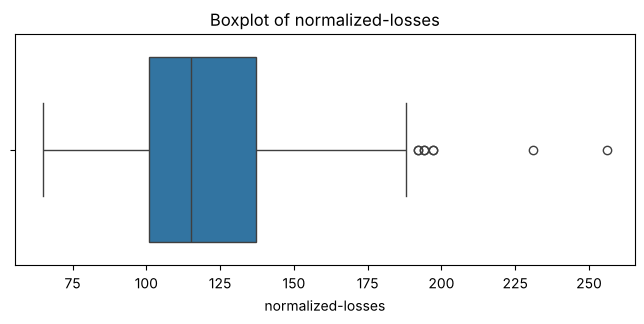

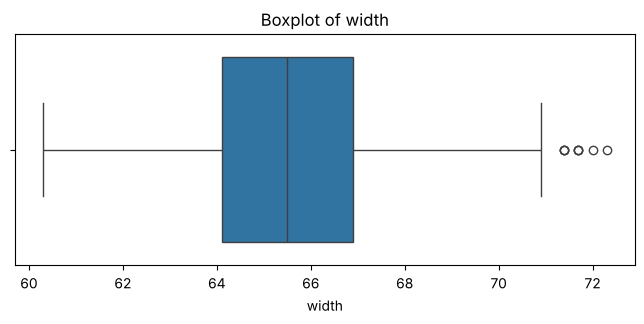

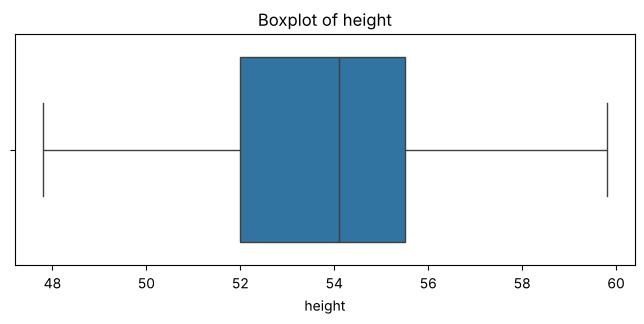

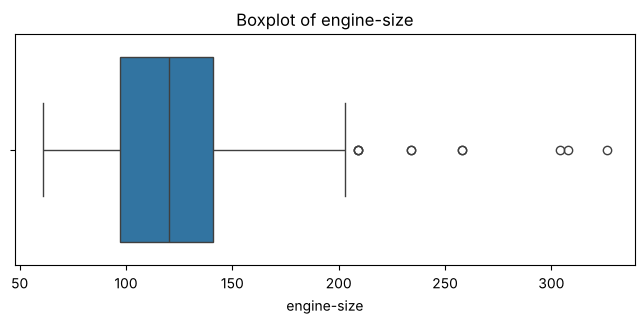

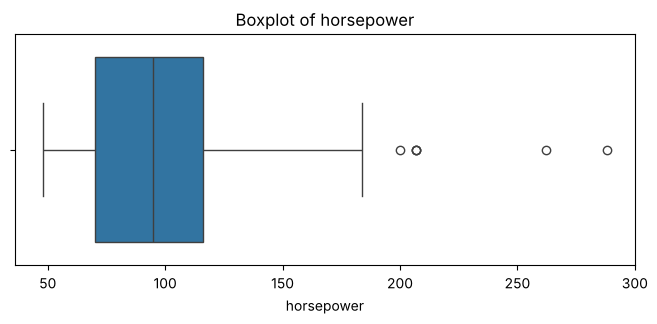

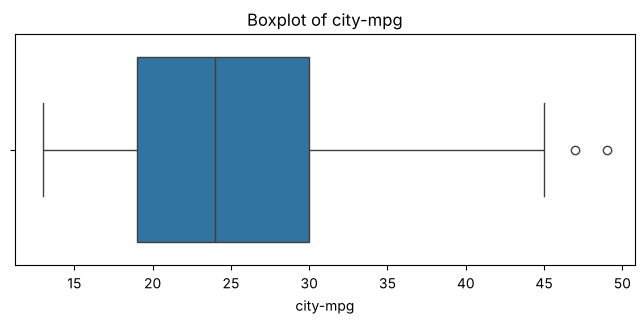

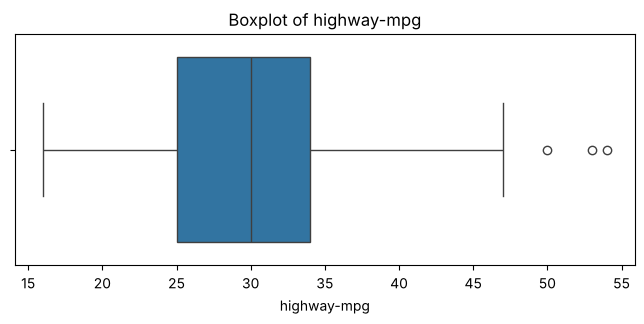

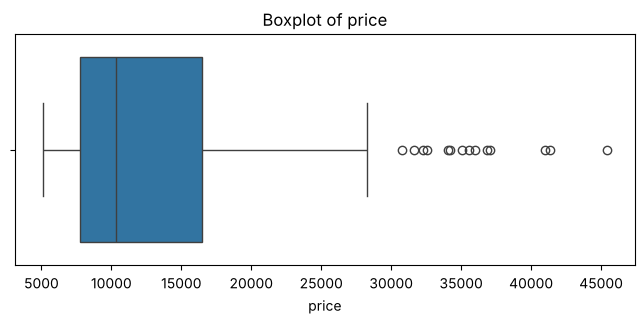

In [19]:
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

#### 5b. Remove outliers: IQR or Z-score?
| Method | Use when | Idea |
|---|---|---|
| **IQR** | Data is **skewed** (not normal) | Anything outside Q1 - 1.5 x IQR or Q3 + 1.5 x IQR is an outlier |
| **Z-score** | Data is **roughly normal** | A value more than 3 standard deviations from the mean is an outlier |

Our columns (price, horsepower, engine-size) are skewed, so we use **IQR**.

**Terms:**
- **Q1 (25th percentile):** 25% of the values are below this.
- **Q3 (75th percentile):** 75% of the values are below this.
- **IQR = Q3 - Q1:** the spread of the middle 50% of the data.
- **Lower bound = Q1 - 1.5 x IQR**, **Upper bound = Q3 + 1.5 x IQR.** The 1.5 is the standard "fence" distance used by statisticians.

**Functions used:**
- `df[col].quantile(0.25)` returns the value below which 25% of the data lies.
- `df = df[(df[col] >= lower) & (df[col] <= upper)]` is **boolean filtering**: keep only rows inside the fence. `&` means "and".
- `df.shape` returns (rows, columns), which we print to see how many rows were removed.

**Real-life example:** A taxi fare list: most trips cost Rs. 100 to 400. IQR draws a fence, and a Rs. 9,000 fare (a data-entry error) falls outside and gets removed.

> **Trade-off to tell students:** Removing outliers column by column is aggressive. Here it drops the dataset from 205 to about 169 rows, and many of the removed rows are real luxury cars (BMW, Jaguar, Mercedes). If the business wants to predict luxury car prices too, you may **cap** the values instead of deleting (this is called winsorization) or keep them. For this lab we follow the lab method.

In [20]:
print("Shape before outlier removal:", df.shape)

num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)
    df = df[
        (df[col] >= lower_bound) &
        (df[col] <= upper_bound)
    ]

print("Shape after outlier removal:", df.shape)

Shape before outlier removal: (205, 15)
Shape after outlier removal: (169, 15)


#### 5c. Verify that no outliers are left
Plot the boxplots again. Most dots beyond the whiskers should be gone.

> **Why a few dots may still appear:** After rows are removed, Q1, Q3 and IQR change a little, so the "fence" moves inward. A few mild new outliers can appear. This is normal. One round of IQR cleaning is enough for the lab.

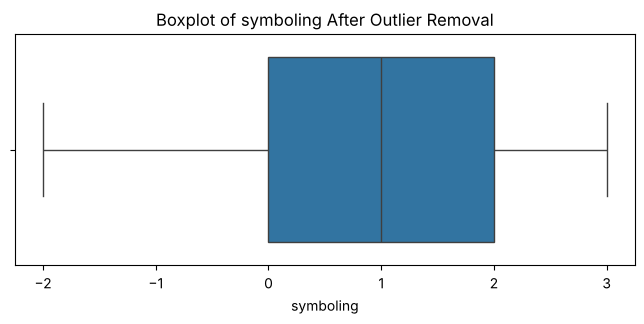

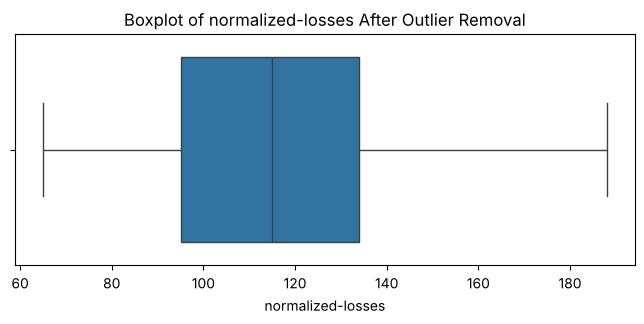

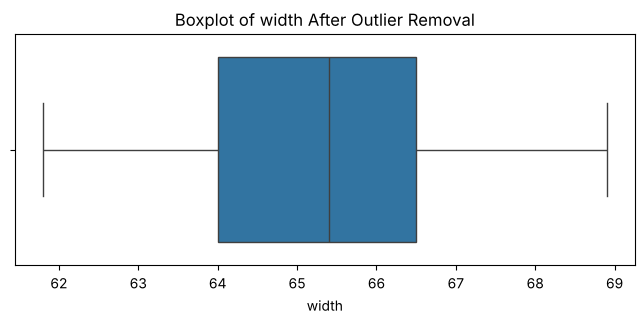

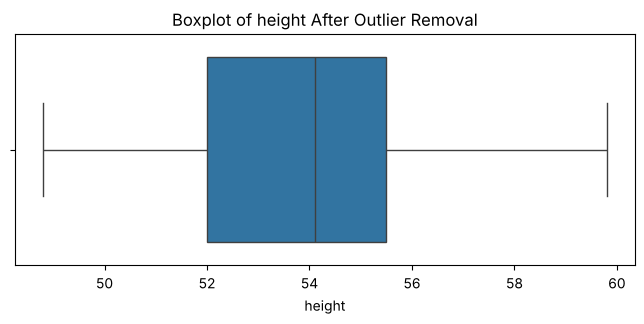

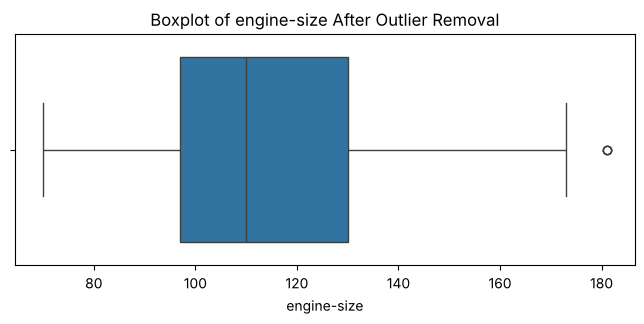

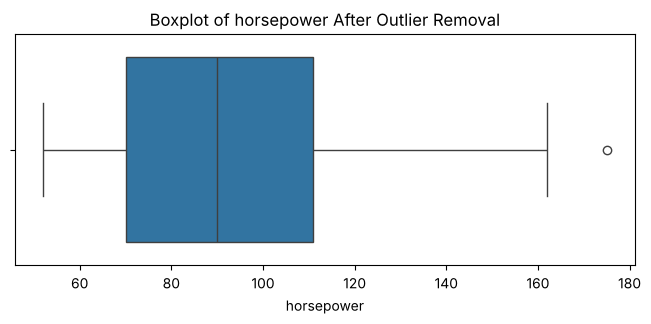

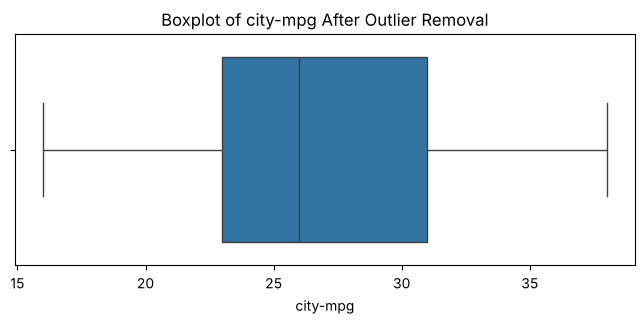

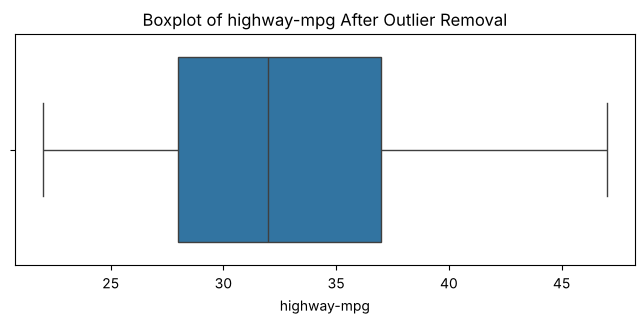

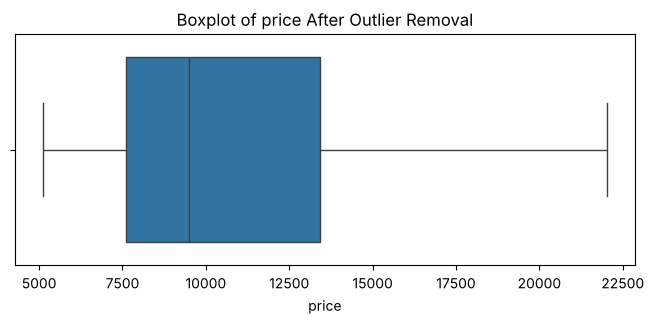

In [21]:
for col in num_cols:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col} After Outlier Removal')
    plt.show()

## Task 5: Encode Categorical Data

### Why is encoding needed?
ML algorithms do math (multiply, add, compare), so they can only work with **numbers**. Columns like `gas`, `diesel`, `sedan` and `hatchback` are text, and they must be converted.

**Real-life example:** An ATM does not understand your name. It understands your card number. Encoding is that "number card" for text.

### Two common techniques
**1. Label Encoding**
- **Definition:** Gives each category a number (0, 1, 2...).
- **Example:** gas = 0, diesel = 1.
- **Best for:** Ordered categories (low < medium < high) or tree-based models.
- **Risk:** For unordered categories like brand names, the model may wrongly think 5 > 2 means "bigger" or "better".

| fuel-type | Encoded |
|---|---|
| gas | 0 |
| diesel | 1 |

**2. One-Hot Encoding**
- **Definition:** Makes a separate 0/1 column for every category.
- **Best for:** Unordered categories (colour, brand, city) and linear models.
- **Risk:** Creates many columns if a category has many values (for example `make` has 22 brands).

| Fuel_Gas | Fuel_Diesel |
|---|---|
| 1 | 0 |
| 0 | 1 |

**Real-life example:** For T-shirt sizes (S < M < L < XL) label encoding makes sense, since there is an order. For city (Pune, Delhi, Chennai) there is no order, so one-hot is safer.

### Step 1: Separate the categorical and numerical columns
**Function:** `df.select_dtypes(include=..., exclude=...)`
- **Definition:** Picks columns by data type.
- **Use case:** Numeric columns go to the model as they are. Text columns need encoding.
- **Note:** The lab uses `select_dtypes(object)`. In the newest pandas, text columns have the type `str`, so `select_dtypes(object)` would return nothing. Using `exclude='number'` works on every pandas version, so we use that.
- **`.copy()`** makes an independent copy, so changing `df_cat` will not give the `SettingWithCopyWarning`.

In [22]:
df_num = df.select_dtypes(include="number")     # int64 and float64 columns
df_cat = df.select_dtypes(exclude="number").copy()   # text columns

print("Numerical columns :", list(df_num.columns))
print("Categorical columns:", list(df_cat.columns))

Numerical columns : ['symboling', 'normalized-losses', 'width', 'height', 'engine-size', 'horsepower', 'city-mpg', 'highway-mpg', 'price']
Categorical columns: ['make', 'fuel-type', 'body-style', 'drive-wheels', 'engine-location', 'engine-type']


### Step 2: Choose the encoding type and apply it
Check the categorical columns first.

**Function:** `df_cat.info()` shows that all of these columns are text with no missing values.

**Which encoding?** The lab uses **Label Encoding** for all of them, so we follow it first.

**Code explained:**
| Code | Meaning / use |
|---|---|
| `from sklearn.preprocessing import LabelEncoder` | Imports the label encoder from scikit-learn, Python's main ML library |
| `le = LabelEncoder()` | Creates an encoder object. We make a new one for every column |
| `le.fit_transform(df_cat[col])` | **fit** learns the unique categories (sorted A to Z), **transform** replaces each with its number |
| `for col in df_cat:` | Loops over the column names, so one loop encodes every categorical column |
| `le.classes_` | Shows the category-to-number order (the position in this list is the code) |

In [23]:
df_cat.info()

<class 'pandas.DataFrame'>
Index: 169 entries, 0 to 202
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   make             169 non-null    str  
 1   fuel-type        169 non-null    str  
 2   body-style       169 non-null    str  
 3   drive-wheels     169 non-null    str  
 4   engine-location  169 non-null    str  
 5   engine-type      169 non-null    str  
dtypes: str(6)
memory usage: 9.2 KB


In [24]:
from sklearn.preprocessing import LabelEncoder

df_cat_original = df_cat.copy()      # keep the text version for comparison

for col in df_cat:
    le = LabelEncoder()              # create the object of LabelEncoder class
    df_cat[col] = le.fit_transform(df_cat[col])
    print(f"{col:16s} ->", {k:int(v) for k,v in zip(le.classes_, le.transform(le.classes_))})

make             -> {'alfa-romero': 0, 'audi': 1, 'bmw': 2, 'chevrolet': 3, 'dodge': 4, 'honda': 5, 'isuzu': 6, 'mazda': 7, 'mercury': 8, 'mitsubishi': 9, 'nissan': 10, 'peugot': 11, 'plymouth': 12, 'porsche': 13, 'renault': 14, 'saab': 15, 'subaru': 16, 'toyota': 17, 'volkswagen': 18, 'volvo': 19}
fuel-type        -> {'diesel': 0, 'gas': 1}
body-style       -> {'convertible': 0, 'hardtop': 1, 'hatchback': 2, 'sedan': 3, 'wagon': 4}
drive-wheels     -> {'4wd': 0, 'fwd': 1, 'rwd': 2}
engine-location  -> {'front': 0}
engine-type      -> {'dohc': 0, 'l': 1, 'ohc': 2, 'ohcf': 3, 'ohcv': 4, 'rotor': 5}


### Step 3: Verify the encoding

In [25]:
print("Before (text):")
display(df_cat_original.head())
print("After (numbers):")
display(df_cat.head())
print("Any text columns left?", len(df_cat.select_dtypes(exclude='number').columns) > 0)

Before (text):


,make,fuel-type,body-style,drive-wheels,engine-location,engine-type
0,alfa-romero,gas,convertible,rwd,front,dohc
1,alfa-romero,gas,convertible,rwd,front,dohc
2,alfa-romero,gas,hatchback,rwd,front,ohcv
3,audi,gas,sedan,fwd,front,ohc
4,audi,gas,sedan,4wd,front,ohc


After (numbers):


,make,fuel-type,body-style,drive-wheels,engine-location,engine-type
0,0,1,0,2,0,0
1,0,1,0,2,0,0
2,0,1,2,2,0,4
3,1,1,3,1,0,2
4,1,1,3,0,0,2


Any text columns left? False


### Bonus: One-Hot Encoding with `pd.get_dummies`
The lab shows both ideas. This is how one-hot looks for `fuel-type`.

**Function:** `pd.get_dummies(df, columns=[...], dtype=int)`
- **Definition:** Makes one 0/1 column per category.
- **`columns=[...]`** is the list of columns to encode.
- **`dtype=int`** gives 0/1 instead of True/False.
- **`drop_first=True`** (optional) drops one column to avoid redundancy. It is useful for linear regression.

In [26]:
pd.get_dummies(df_cat_original[['fuel-type']], columns=['fuel-type'], dtype=int).head()

,fuel-type_diesel,fuel-type_gas
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


### Which encoding for which column here?
| Column | Type | Suggested encoding | Reason |
|---|---|---|---|
| `fuel-type` | 2 categories | Label or One-hot | Only gas/diesel, so either is safe |
| `engine-location` | 2 categories | Label or One-hot | Same reason |
| `make`, `body-style`, `drive-wheels`, `engine-type` | No natural order | **One-hot** (preferred for linear regression) | Label numbers imply a fake order |

The lab uses label encoding to keep the dataset simple. In the next lab (scaling, feature selection) and during model building, you can switch to one-hot.

### Final prepared dataset
Combine the numerical and encoded categorical columns into one clean table.

In [27]:
df_final = pd.concat([df_num, df_cat], axis=1)
print("Final shape:", df_final.shape)
print("Missing values:", int(df_final.isnull().sum().sum()))
print("All numeric?", all(pd.api.types.is_numeric_dtype(t) for t in df_final.dtypes))
df_final.head()

Final shape: (169, 15)
Missing values: 0
All numeric? True


,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price,make,fuel-type,body-style,drive-wheels,engine-location,engine-type
0,3,115.0,64.1,48.8,130,111.0,21,27,13495,0,1,0,2,0,0
1,3,115.0,64.1,48.8,130,111.0,21,27,16500,0,1,0,2,0,0
2,1,115.0,65.5,52.4,152,154.0,19,26,16500,0,1,2,2,0,4
3,2,164.0,66.2,54.3,109,102.0,24,30,13950,1,1,3,1,0,2
4,2,164.0,66.4,54.3,136,115.0,18,22,17450,1,1,3,0,0,2


## Lab Summary
| Task | What we did | Key functions |
|---|---|---|
| 1 | Defined **price** as the target and the others as features. This is a **regression** problem | n/a |
| 2 | Loaded and inspected the data | `read_csv`, `head`, `info`, `describe` |
| 3 | Studied the distributions (all right-skewed) | `hist` |
| 4 | Cleaned the data | `replace`, `to_numeric`, `isnull().sum()`, `skew`, `fillna`, `duplicated`, `boxplot`, `quantile` (IQR) |
| 5 | Converted text to numbers | `select_dtypes`, `LabelEncoder`, `get_dummies` |

**Result:** The dataset is clean, numeric and ready for the next steps: scaling, feature selection and model building.

### Checkpoint questions for students
1. Why is `price` the target and not `horsepower`?
2. Why did we use the median instead of the mean for `normalized-losses`?
3. What is the difference between label encoding and one-hot encoding? When is each one risky?
4. Why can removing outliers be harmful for a luxury-car price model?
5. Which function tells us how many values are missing in each column?

### Next lab preparation
Data scaling (Min-Max, Standardization), feature selection and feature engineering, and handling imbalanced data (SMOTE, undersampling, oversampling).